# 01 — Tiền xử lý: phân nhóm khách hàng và hưởng ứng marketing

**Bản chốt ngày 05/11/2026**, chỉnh từ notebook đã chạy do ChinhBui cung cấp. Phụ trách: ChinhBui (làm sạch), Tuananh (pipeline và ghép).

Quy trình: **quy tắc làm sạch cố định → nhóm trùng theo X → test cố định 20% → ba tỷ lệ trong development → fit riêng trên từng train**.

- Test được bảo toàn; notebook không impute, encode, scale hoặc giảm chiều test.
- Giữ 2.236 khách hàng sau lọc 4 ngoại lai. Không xóa hồ sơ giống nhau nhưng khác ID, không dùng nhãn để chia nhóm trùng.
- Giữ Education như category, Marital lạ thành Unknown, ngày tham chiếu cố định 30/06/2014. Không tự thêm quy tắc bỏ khách có chi tiêu nhưng số mua bằng 0.
- Không tạo bản fit toàn bộ dữ liệu. Biểu đồ khám phá dùng development; thống kê sau chuẩn hóa dùng train 80:20.
- PCA còn `max(1, floor(d/3))` chiều, với `d` sau mã hóa trên train. Đây là chuẩn bị đầu vào; thống kê PCA chi tiết và so sánh Kernel PCA thuộc notebook 02.

Nguồn dữ liệu: Kaggle Customer Personality Analysis. Các mô tả tổng thể trước đây đã xem cả dữ liệu; test này được giữ cố định từ lúc chốt, không thể tuyên bố hoàn toàn chưa từng được quan sát.

In [1]:
from pathlib import Path
import sys, json, hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/preprocessing.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import config, preprocessing, data_splitting
from src.experiment_preprocessing import make_feature_pipeline

config.ensure_dirs()
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)
FIGURES = config.FIGURES_PREPROCESSING_DIR
TABLES = config.TABLES_DIR
OUTPUT = config.PROCESSED_DATA_DIR / 'experiments'
OUTPUT.mkdir(parents=True, exist_ok=True)

def save_figure(name):
    plt.gcf().savefig(FIGURES / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def snapshot_splits():
    return {p.name: (hashlib.sha256(p.read_bytes()).hexdigest(), p.stat().st_mtime_ns)
            for p in config.SPLITS_DIR.iterdir() if p.is_file()} if config.SPLITS_DIR.exists() else {}

before_splits = snapshot_splits()
raw = preprocessing.load_raw()
cleaned, metadata = preprocessing.create_handoff(raw)
manifest = data_splitting.export_splits(raw)  # Chỉ xác minh nếu các tập đã tồn tại.
frozen_snapshot = snapshot_splits()
if before_splits:
    assert before_splits == frozen_snapshot
cleaning_summary = preprocessing.export_handoff(raw)
assignments = pd.read_csv(config.SPLITS_DIR / 'assignments.csv', dtype={'duplicate_group': str})
development_mask = assignments.partition.eq('development')
development = cleaned.loc[development_mask].copy()
raw_development = raw.iloc[assignments.loc[development_mask, 'source_row']].copy()
split_summary = pd.DataFrame(manifest['summary'])
split_summary.to_csv(TABLES / 'data_split_summary.csv', index=False)
display(split_summary)
print('Nguồn:', raw.shape, '| Sau quy tắc cố định:', cleaned.shape)
print('Test chỉ được kiểm tra tính toàn vẹn; không đưa vào pipeline.')

,partition,rows,parent_rows,fraction_of_parent,response_0,response_1,response_1_rate,groups
0,development,1788,2236,0.799642,1521,267,0.149329,1625
1,test,448,2236,0.200358,381,67,0.149554,408
2,train_80_20,1430,1788,0.799776,1217,213,0.148951,1300
3,validation_80_20,358,1788,0.200224,304,54,0.150838,325
4,train_70_30,1250,1788,0.699105,1064,186,0.148800,1136
5,validation_70_30,538,1788,0.300895,457,81,0.150558,489
6,train_60_40,1072,1788,0.599553,912,160,0.149254,973
7,validation_60_40,716,1788,0.400447,609,107,0.149441,652


Nguồn: (2240, 29) | Sau quy tắc cố định: (2236, 32)
Test chỉ được kiểm tra tính toàn vẹn; không đưa vào pipeline.


## 1. Từ điển dữ liệu và thống kê mô tả

Từ điển giữ mô tả trường của bản được gửi. Các thống kê và biểu đồ bên dưới chỉ dùng khách hàng trong development. Không dùng chúng để thay đổi các quy tắc lọc đã khóa.

In [2]:
FIELD_INFO = {
    'ID': ('Không dùng', 'định danh', 'Mã định danh khách hàng'),
    'Year_Birth': ('Nhân khẩu', 'số (rời rạc)', 'Năm sinh'),
    'Education': ('Nhân khẩu', 'ordinal', 'Trình độ học vấn'),
    'Marital_Status': ('Nhân khẩu', 'nominal', 'Tình trạng hôn nhân'),
    'Income': ('Nhân khẩu', 'số (liên tục)', 'Thu nhập hộ gia đình hàng năm'),
    'Kidhome': ('Nhân khẩu', 'số (rời rạc)', 'Số trẻ nhỏ trong nhà'),
    'Teenhome': ('Nhân khẩu', 'số (rời rạc)', 'Số thiếu niên trong nhà'),
    'Dt_Customer': ('Nhân khẩu', 'ngày', 'Ngày đăng ký làm khách hàng (dd-mm-yyyy)'),
    'Recency': ('Hành vi mua', 'số (rời rạc)', 'Số ngày kể từ lần mua hàng gần nhất'),
    'MntWines': ('Hành vi mua', 'số (liên tục)', 'Chi tiêu cho rượu vang (2 năm gần nhất)'),
    'MntFruits': ('Hành vi mua', 'số (liên tục)', 'Chi tiêu cho trái cây'),
    'MntMeatProducts': ('Hành vi mua', 'số (liên tục)', 'Chi tiêu cho thịt'),
    'MntFishProducts': ('Hành vi mua', 'số (liên tục)', 'Chi tiêu cho cá'),
    'MntSweetProducts': ('Hành vi mua', 'số (liên tục)', 'Chi tiêu cho đồ ngọt'),
    'MntGoldProds': ('Hành vi mua', 'số (liên tục)', 'Chi tiêu cho vàng/trang sức'),
    'NumDealsPurchases': ('Hành vi mua', 'số (rời rạc)', 'Số lần mua có khuyến mãi'),
    'NumWebPurchases': ('Hành vi mua', 'số (rời rạc)', 'Số lần mua qua website'),
    'NumCatalogPurchases': ('Hành vi mua', 'số (rời rạc)', 'Số lần mua qua catalog'),
    'NumStorePurchases': ('Hành vi mua', 'số (rời rạc)', 'Số lần mua trực tiếp tại cửa hàng'),
    'NumWebVisitsMonth': ('Hành vi mua', 'số (rời rạc)', 'Số lần truy cập website mỗi tháng'),
    'AcceptedCmp1': ('Chiến dịch', 'nhị phân', 'Chấp nhận chiến dịch 1 (0/1)'),
    'AcceptedCmp2': ('Chiến dịch', 'nhị phân', 'Chấp nhận chiến dịch 2 (0/1)'),
    'AcceptedCmp3': ('Chiến dịch', 'nhị phân', 'Chấp nhận chiến dịch 3 (0/1)'),
    'AcceptedCmp4': ('Chiến dịch', 'nhị phân', 'Chấp nhận chiến dịch 4 (0/1)'),
    'AcceptedCmp5': ('Chiến dịch', 'nhị phân', 'Chấp nhận chiến dịch 5 (0/1)'),
    'Complain': ('Chiến dịch', 'nhị phân', 'Đã phàn nàn trong 2 năm gần nhất (0/1)'),
    'Z_CostContact': ('Không dùng', 'hằng số', 'Chi phí liên hệ (hằng số)'),
    'Z_Revenue': ('Không dùng', 'hằng số', 'Doanh thu (hằng số)'),
    'Response': ('Nhãn', 'nhị phân', 'Chấp nhận chiến dịch cuối (NHÃN: 0/1)'),
}
dictionary = pd.DataFrame.from_dict(FIELD_INFO, orient='index', columns=['group', 'kind', 'description']).rename_axis('column')
dictionary.loc['Education', 'kind'] = 'category (one-hot; không áp đặt thứ bậc)'
dictionary.to_csv(TABLES / 'data_dictionary.csv', encoding='utf-8-sig')
display(dictionary)
profile = pd.DataFrame({'dtype': raw_development.dtypes.astype(str),
                        'missing': raw_development.isna().sum(),
                        'unique': raw_development.nunique()})
display(profile)
stats = raw_development.describe().T
stats['skew'] = raw_development.select_dtypes('number').skew()
stats.to_csv(TABLES / 'development_raw_statistics.csv')
display(stats)

,group,kind,description
column,,,
ID,Không dùng,định danh,Mã định danh khách hàng
Year_Birth,Nhân khẩu,số (rời rạc),Năm sinh
Education,Nhân khẩu,category (one-hot; không áp đặt thứ bậc),Trình độ học vấn
Marital_Status,Nhân khẩu,nominal,Tình trạng hôn nhân
Income,Nhân khẩu,số (liên tục),Thu nhập hộ gia đình hàng năm
Kidhome,Nhân khẩu,số (rời rạc),Số trẻ nhỏ trong nhà
Teenhome,Nhân khẩu,số (rời rạc),Số thiếu niên trong nhà
Dt_Customer,Nhân khẩu,ngày,Ngày đăng ký làm khách hàng (dd-mm-yyyy)
Recency,Hành vi mua,số (rời rạc),Số ngày kể từ lần mua hàng gần nhất


,dtype,missing,unique
ID,int64,0,1788
Year_Birth,int64,0,54
Education,object,0,5
Marital_Status,object,0,7
Income,float64,18,1579
Kidhome,int64,0,3
Teenhome,int64,0,3
Dt_Customer,object,0,629
Recency,int64,0,100
MntWines,int64,0,680


,count,mean,std,min,25%,50%,75%,max,skew
ID,1788.0,5594.274609,3245.955798,1.0,2859.00,5511.0,8415.00,11191.0,0.039149
Year_Birth,1788.0,1969.072148,11.632204,1943.0,1960.00,1970.0,1977.00,1996.0,-0.098081
Income,1770.0,51737.925989,21692.658108,1730.0,34935.00,51171.5,68146.50,162397.0,0.373549
Kidhome,1788.0,0.446309,0.538317,0.0,0.00,0.0,1.00,2.0,0.623761
Teenhome,1788.0,0.502237,0.543049,0.0,0.00,0.0,1.00,2.0,0.410908
Recency,1788.0,49.643177,29.045999,0.0,25.00,50.0,75.00,99.0,-0.023841
MntWines,1788.0,301.543624,336.528427,0.0,23.00,172.0,493.00,1493.0,1.203332
MntFruits,1788.0,25.884228,39.866208,0.0,1.00,8.0,32.00,199.0,2.161688
MntMeatProducts,1788.0,164.612416,223.483767,0.0,15.75,66.0,223.00,1725.0,2.122666
MntFishProducts,1788.0,36.920582,54.020860,0.0,3.00,12.0,47.00,259.0,1.950545


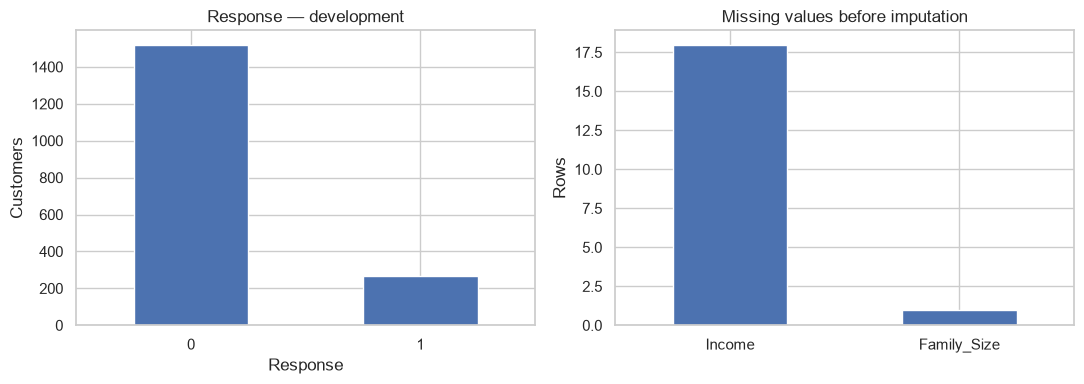

Response
0    0.850671
1    0.149329
Name: fraction, dtype: float64

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
development.Response.value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Response — development', xlabel='Response', ylabel='Customers')
missing = development.isna().sum()
missing[missing.gt(0)].plot.bar(ax=axes[1], rot=0)
axes[1].set(title='Missing values before imputation', ylabel='Rows')
plt.tight_layout()
save_figure('development_response_missing')
display(development.Response.value_counts(normalize=True).rename('fraction'))

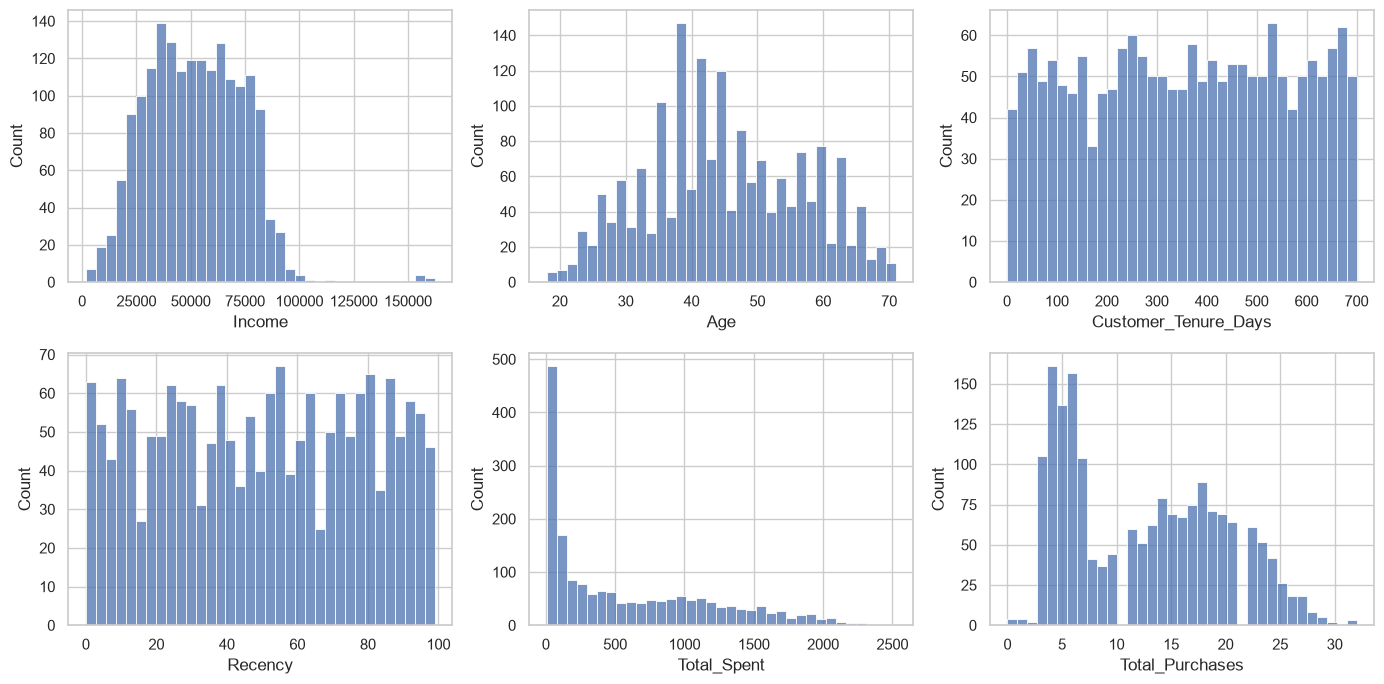

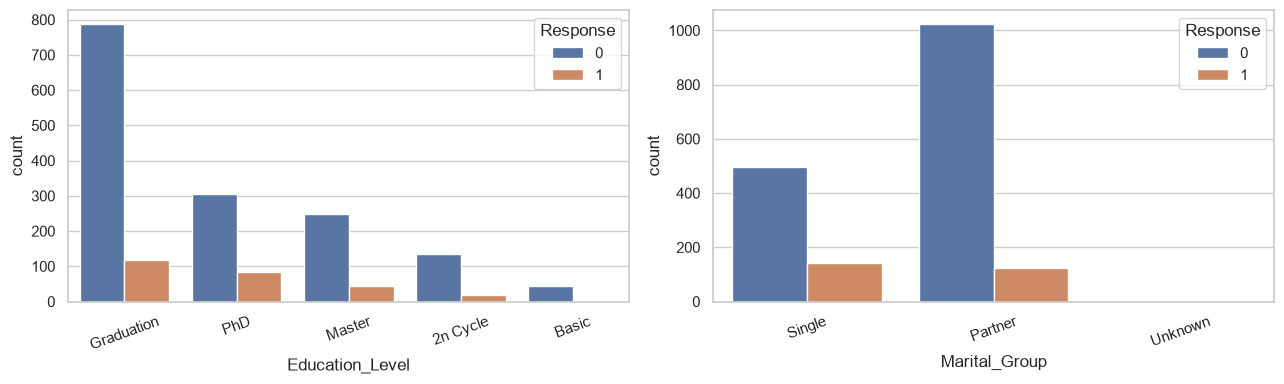

In [4]:
columns = ['Income', 'Age', 'Customer_Tenure_Days', 'Recency', 'Total_Spent', 'Total_Purchases']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, ax in zip(columns, axes.flat):
    sns.histplot(data=development, x=col, bins=35, ax=ax)
plt.tight_layout()
save_figure('development_numeric_distributions')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col, ax in zip(['Education_Level', 'Marital_Group'], axes):
    sns.countplot(data=development, x=col, hue='Response', ax=ax)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
save_figure('development_categories_response')

## 2. Làm sạch theo quy tắc cố định và giữ nhóm trùng

| Trường | Quy tắc |
|---|---|
| Year_Birth | Giữ từ 1920 đến 2014 |
| Income | Bỏ >200.000; số âm thành NaN; giữ thiếu để điền bằng median của train |
| ID, Z_CostContact, Z_Revenue | Loại khỏi đầu vào; ID giữ riêng trong metadata |
| Marital_Status | Partner / Single / Unknown; không loại Absurd, YOLO |
| Education | Giữ 5 nhãn, one-hot trên train; không gán thứ bậc chưa có căn cứ |
| Trùng | Chỉ bỏ bản ghi trùng hoàn toàn; các ID khác nhau có X giống nhau nằm cùng nhóm |

Không dùng IQR hay percentile từ toàn bộ dữ liệu để học ngưỡng lọc. Chi tiêu cao được giữ nếu không vi phạm quy tắc cố định; không tự chọn log-transform dựa trên cả dataset.

,value
schema_version,1
reference_date,2014-06-30
raw_rows,2240
raw_columns,29
exact_duplicates_removed,0
birth_outliers,3
income_outliers,1
outlier_rows_removed,4
cleaned_rows,2236
features,31


Nhóm có nhiều khách hàng: 194
Dòng trùng X sau dòng đầu: 203


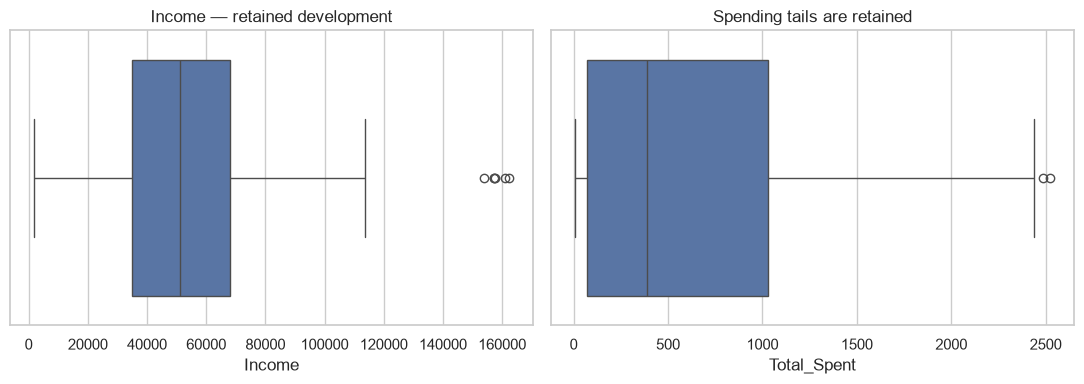

In [5]:
display(pd.Series(cleaning_summary, name='value').to_frame())
assert 'Response' not in manifest['features']
assert not set(['ID', 'Z_CostContact', 'Z_Revenue']).intersection(manifest['features'])
assert cleaned.shape[0] == len(assignments)
assert metadata.duplicate_group.equals(assignments.duplicate_group)
group_counts = metadata.duplicate_group.value_counts()
print('Nhóm có nhiều khách hàng:', int(group_counts.gt(1).sum()))
print('Dòng trùng X sau dòng đầu:', int(metadata.duplicate_group.duplicated().sum()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=raw_development, x='Income', ax=axes[0])
sns.boxplot(data=development, x='Total_Spent', ax=axes[1])
axes[0].set_title('Income — retained development')
axes[1].set_title('Spending tails are retained')
plt.tight_layout()
save_figure('development_outlier_review')

## 3. Đặc trưng được tạo

- `Age = 2014 − Year_Birth`; `Customer_Tenure_Days = 30/06/2014 − Dt_Customer`.
- `Total_Spent`: tổng 6 cột Mnt; `Total_Purchases`: Web + Catalog + Store. Không cộng Deals vì đây là số lần mua giảm giá, không phải kênh riêng.
- `Total_Accepted_Cmp`: tổng AcceptedCmp1–5, không gồm Response.
- `Children = Kidhome + Teenhome`; `Is_Parent = Children > 0`.
- `Family_Size`: Children + 2 nếu Partner, +1 nếu Single, NaN nếu Unknown.

Các tổng tạo tương quan với thành phần: cần nêu khi phân tích PCA và giả định độc lập của NB. Các biến lịch sử được giả định đã có trước chiến dịch mục tiêu; dataset chưa đủ mốc thời gian để xác minh hoàn toàn giả định này.

,column,dtype,role,missing_development
0,Income,float64,feature,18
1,Kidhome,int64,feature,0
2,Teenhome,int64,feature,0
3,Recency,int64,feature,0
4,MntWines,int64,feature,0
5,MntFruits,int64,feature,0
6,MntMeatProducts,int64,feature,0
7,MntFishProducts,int64,feature,0
8,MntSweetProducts,int64,feature,0
9,MntGoldProds,int64,feature,0


29 cột số + 2 category trước mã hóa
Category: ['Marital_Group', 'Education_Level']


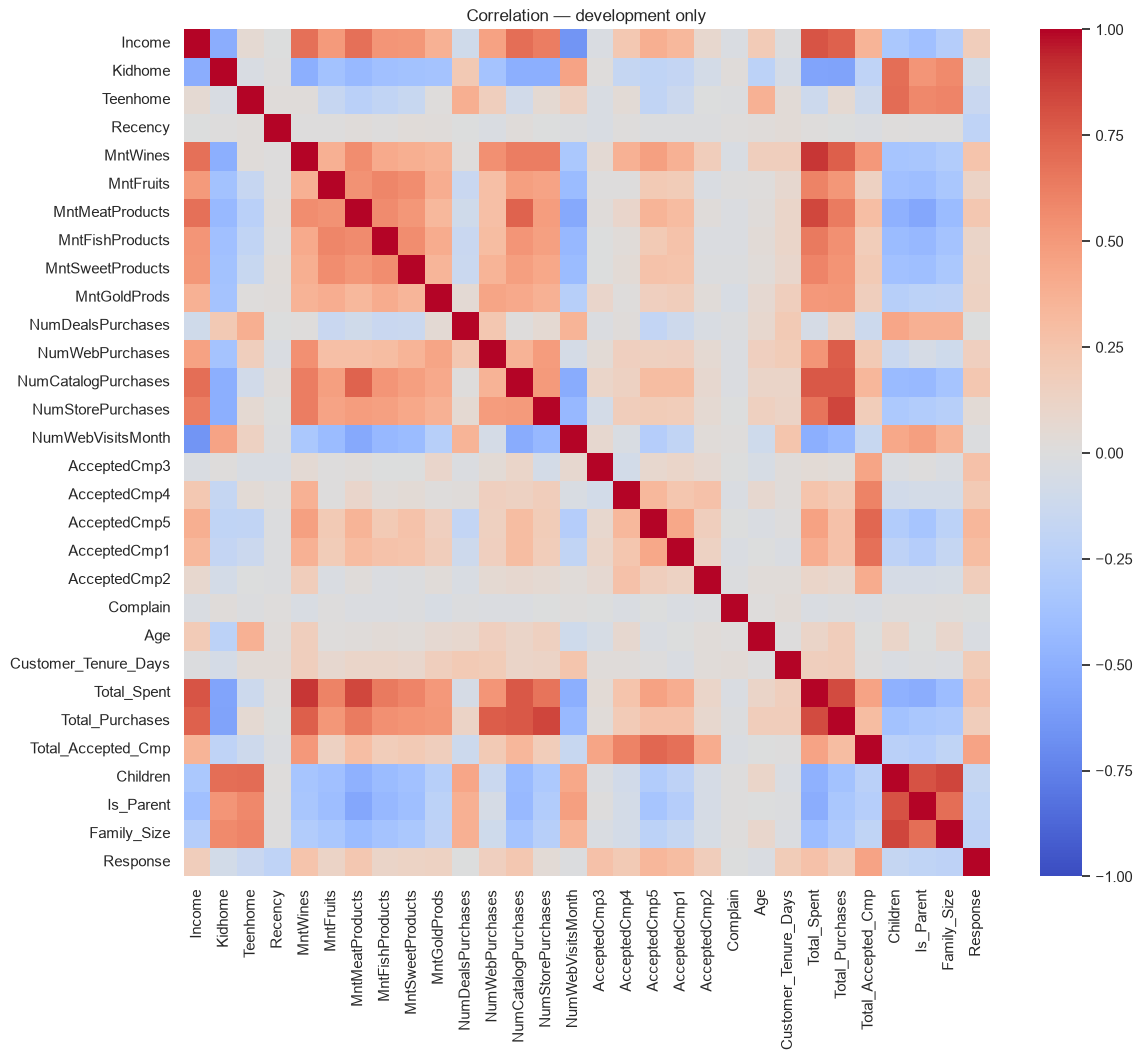

In [6]:
numeric_cols, categorical_cols = preprocessing.split_feature_types(development)
schema = pd.DataFrame({'column': development.columns, 'dtype': development.dtypes.astype(str).values,
                       'role': ['target' if c == 'Response' else 'feature' for c in development],
                       'missing_development': development.isna().sum().values})
display(schema)
print(f'{len(numeric_cols)} cột số + {len(categorical_cols)} category trước mã hóa')
print('Category:', categorical_cols)
corr = development[numeric_cols + ['Response']].corr()
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation — development only')
save_figure('development_correlation')

## 4. Ba tập chia trong development và pipeline riêng

Test cố định theo nhóm, có stratification theo Response. Trong development dùng các fold đã lưu để lấy tỷ lệ gần 80:20, 70:30, 60:40; chênh lệch nhỏ do phải giữ nguyên nhóm.

Mỗi train có pipeline mới: số → median → StandardScaler; category → most frequent → one-hot (`handle_unknown='ignore'`). PCA học trên đầu ra đã chuẩn hóa của chính train đó. Validation chỉ `transform`. Cột hoàn toàn thiếu ở train được giữ và điền 0 theo chính sách của SimpleImputer; category mới ở validation tạo vector 0, không mở thêm cột.

Không bắt các tập chia khác nhau có cùng số cột one-hot; chỉ train và validation trong cùng tập chia phải đồng nhất.

In [7]:
experiments = {}
checks = []
test_groups = set(assignments.loc[~development_mask, 'duplicate_group'])
for name, n_validation_folds in [('80_20', 2), ('70_30', 3), ('60_40', 4)]:
    train_mask = development_mask & assignments.development_fold.ge(n_validation_folds)
    val_mask = development_mask & assignments.development_fold.lt(n_validation_folds)
    train_meta = assignments.loc[train_mask].reset_index(drop=True)
    val_meta = assignments.loc[val_mask].reset_index(drop=True)
    train = pd.read_csv(config.SPLITS_DIR / f'train_{name}.csv')
    validation = pd.read_csv(config.SPLITS_DIR / f'validation_{name}.csv')
    # Xác minh thứ tự metadata khớp CSV, không chỉ số hàng.
    pd.testing.assert_frame_equal(train, cleaned.loc[train_mask].reset_index(drop=True), check_dtype=False)
    pd.testing.assert_frame_equal(validation, cleaned.loc[val_mask].reset_index(drop=True), check_dtype=False)
    train_groups, val_groups = set(train_meta.duplicate_group), set(val_meta.duplicate_group)
    assert train_groups.isdisjoint(val_groups)
    assert (train_groups | val_groups).isdisjoint(test_groups)
    assert len(train) + len(validation) == len(development)
    X_train, y_train = train.drop(columns='Response'), train.Response
    X_val, y_val = validation.drop(columns='Response'), validation.Response
    pipeline = make_feature_pipeline(X_train, reduce=True)
    train_pca = pipeline.fit_transform(X_train)
    val_pca = pipeline.transform(X_val)
    pre = pipeline.named_steps['preprocessor']
    names = pre.get_feature_names_out()
    train_encoded = pd.DataFrame(pre.transform(X_train), columns=names)
    val_encoded = pd.DataFrame(pre.transform(X_val), columns=names)
    pca = pipeline.named_steps['pca']
    for array in [train_encoded, val_encoded, train_pca, val_pca]:
        assert np.isfinite(np.asarray(array)).all()
    assert pca.pca_.n_samples_ == len(train)
    assert train_pca.shape[1] == max(1, train_encoded.shape[1] // 3)
    num = pre.named_transformers_['num']
    expected_medians = X_train[numeric_cols].median().fillna(0).to_numpy()
    np.testing.assert_allclose(num.named_steps['imputer'].statistics_, expected_medians)
    np.testing.assert_allclose(train_encoded.filter(like='num__').mean(), 0, atol=1e-10)
    checks.append({'split': name, 'train_rows': len(train), 'validation_rows': len(validation),
                   'train_response_1': y_train.mean(), 'validation_response_1': y_val.mean(),
                   'features_encoded': len(names), 'features_pca': train_pca.shape[1],
                   'pca_explained_variance_ratio_sum': pca.pca_.explained_variance_ratio_.sum(),
                   'Income_train_median': X_train.Income.median(), 'group_overlap': 0})
    experiments[name] = dict(pipeline=pipeline, X_train=X_train, X_val=X_val,
                             y_train=y_train, y_val=y_val, train_encoded=train_encoded,
                             val_encoded=val_encoded, train_pca=train_pca, val_pca=val_pca,
                             train_metadata=train_meta, validation_metadata=val_meta)
experiment_summary = pd.DataFrame(checks)
experiment_summary.to_csv(TABLES / 'train_preprocessing_summary.csv', index=False)
display(experiment_summary)

,split,train_rows,validation_rows,train_response_1,validation_response_1,features_encoded,features_pca,pca_explained_variance_ratio_sum,Income_train_median,group_overlap
0,80_20,1430,358,0.148951,0.150838,37,12,0.801694,51369.0,0
1,70_30,1250,538,0.148800,0.150558,37,12,0.801994,51012.0,0
2,60_40,1072,716,0.149254,0.149441,37,12,0.804850,50326.5,0


## 5. Kiểm tra và trực quan hóa sau tiền xử lý

Dùng train của kịch bản 80:20 để minh họa. Mean gần 0 và std dân số (`ddof=0`) gần 1 chỉ áp dụng cột số không hằng của train; không yêu cầu validation có mean 0/std 1. Cột one-hot là 0/1, không áp dụng kiểm tra chuẩn hóa số.

,count,mean,std,min,25%,50%,75%,max,std_population,skew
num__Income,1430.0,-1.192519e-16,1.000350,-2.356907,-0.758379,-0.019838,0.734133,5.207503,1.000000,0.332795
num__Kidhome,1430.0,3.229740e-17,1.000350,-0.826645,-0.826645,-0.826645,1.029088,2.884822,1.000000,0.633839
num__Teenhome,1430.0,-6.459479e-17,1.000350,-0.936921,-0.936921,-0.936921,0.900935,2.738792,1.000000,0.391388
num__Recency,1430.0,1.105565e-16,1.000350,-1.728580,-0.863164,0.036868,0.867667,1.698466,1.000000,-0.043642
num__MntWines,1430.0,9.937661e-18,1.000350,-0.897601,-0.825785,-0.385270,0.557951,3.523842,1.000000,1.235580
num__MntFruits,1430.0,-2.360194e-17,1.000350,-0.651453,-0.626342,-0.450568,0.152086,4.345551,1.000000,2.166732
num__MntMeatProducts,1430.0,4.968830e-17,1.000350,-0.734361,-0.663337,-0.441387,0.258867,6.922931,1.000000,2.191924
num__MntFishProducts,1430.0,3.478181e-17,1.000350,-0.674466,-0.637820,-0.472913,0.168392,4.052868,1.000000,1.953608
num__MntSweetProducts,1430.0,2.981298e-17,1.000350,-0.639498,-0.615187,-0.445005,0.138474,5.754464,1.000000,2.275471
num__MntGoldProds,1430.0,4.720389e-17,1.000350,-0.841783,-0.672289,-0.370965,0.226974,5.975662,1.000000,1.888051


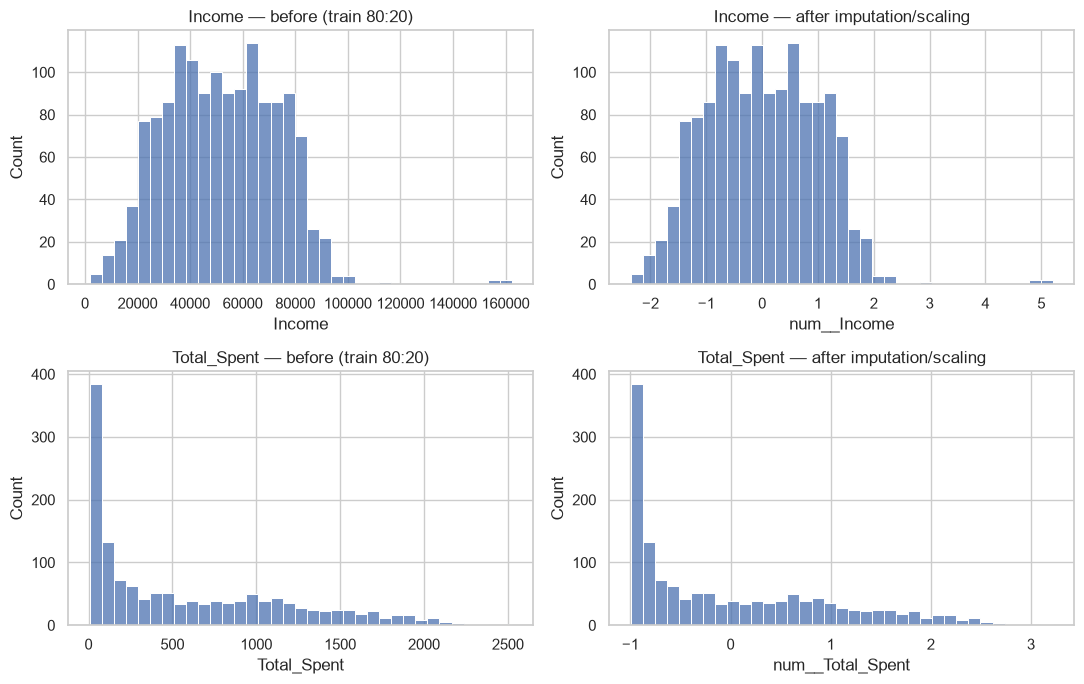

In [8]:
example = experiments['80_20']
encoded = example['train_encoded']
after_stats = encoded.describe().T
after_stats['std_population'] = encoded.std(ddof=0)
after_stats['skew'] = encoded.skew()
after_stats.to_csv(TABLES / 'train_80_20_after_statistics.csv')
display(after_stats)
num_encoded = encoded.filter(like='num__')
std = num_encoded.std(ddof=0)
np.testing.assert_allclose(std[std.gt(1e-12)], 1, atol=1e-10)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, col in enumerate(['Income', 'Total_Spent']):
    sns.histplot(example['X_train'][col], bins=35, ax=axes[row, 0])
    axes[row, 0].set_title(f'{col} — before (train 80:20)')
    sns.histplot(encoded[f'num__{col}'], bins=35, ax=axes[row, 1])
    axes[row, 1].set_title(f'{col} — after imputation/scaling')
plt.tight_layout()
save_figure('train_80_20_before_after')

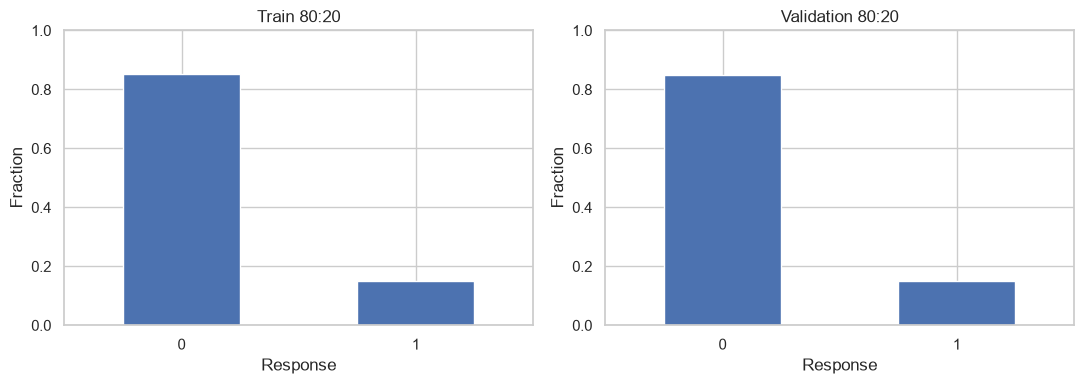

Nhãn giữ nguyên; chưa resample hoặc thay đổi tỷ lệ lớp.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
example['y_train'].value_counts(normalize=True).sort_index().plot.bar(ax=axes[0], rot=0)
example['y_val'].value_counts(normalize=True).sort_index().plot.bar(ax=axes[1], rot=0)
for ax, title in zip(axes, ['Train 80:20', 'Validation 80:20']):
    ax.set(title=title, ylabel='Fraction', ylim=(0, 1), xlabel='Response')
plt.tight_layout()
save_figure('train_validation_response_80_20')
print('Nhãn giữ nguyên; chưa resample hoặc thay đổi tỷ lệ lớp.')

## 6. Xuất dữ liệu train/validation và kiểm tra test bất biến

Mỗi thư mục `data/processed/experiments/<tỷ_lệ>/` chứa X sau mã hóa, X sau PCA, y, metadata cùng thứ tự và pipeline đã fit. Các file dữ liệu/model nằm ngoài Git theo `.gitignore`. Không xuất bất kỳ bản test đã biến đổi nào.

`feature_pipeline.joblib` nhận 31 cột X sạch và trả về PCA; lấy `pipeline.named_steps['preprocessor']` để transform không giảm chiều. Không fit lại đối tượng đã lưu trên validation.

In [10]:
for name, result in experiments.items():
    directory = OUTPUT / name
    directory.mkdir(parents=True, exist_ok=True)
    for role, short in [('train', 'train'), ('validation', 'val')]:
        result[f'{short}_encoded'].to_csv(directory / f'X_{role}_encoded.csv', index=False)
        reduced = pd.DataFrame(result[f'{short}_pca'], columns=result['pipeline'].named_steps['pca'].get_feature_names_out())
        reduced.to_csv(directory / f'X_{role}_pca.csv', index=False)
        result[f'y_{short}'].to_csv(directory / f'y_{role}.csv', index=False)
        result[f'{role}_metadata'].to_csv(directory / f'{role}_metadata.csv', index=False)
    joblib.dump(result['pipeline'], directory / 'feature_pipeline.joblib')
    restored = joblib.load(directory / 'feature_pipeline.joblib')
    np.testing.assert_allclose(restored.transform(result['X_val']), result['val_pca'])

assert snapshot_splits() == frozen_snapshot, 'Một file chia tập đã bị thay đổi!'
audit = {'frozen_splits_unchanged_bytes_and_mtime': True,
         'test_transformed': False, 'test_used_for_fit': False,
         'fit_scope': 'training partition independently for each development split',
         'reduction_rule': 'max(1, floor(encoded_train_dimensions / 3))',
         'split_manifest_sha256': frozen_snapshot['manifest.json'][0],
         'experiments': experiment_summary.to_dict(orient='records')}
(TABLES / 'train_preprocessing_audit.json').write_text(json.dumps(audit, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
display(pd.Series({k: v for k, v in audit.items() if k != 'experiments'}))
print('Hoàn tất: dữ liệu hữu hạn; metadata khớp; nhóm không giao nhau; test và mọi file splits giữ nguyên byte và mtime.')

frozen_splits_unchanged_bytes_and_mtime                                                 True
test_transformed                                                                       False
test_used_for_fit                                                                      False
fit_scope                                  training partition independently for each deve...
reduction_rule                                   max(1, floor(encoded_train_dimensions / 3))
split_manifest_sha256                      47f90422b3827bbd12f1e6ca12163afd014da3225b77da...
dtype: object

Hoàn tất: dữ liệu hữu hạn; metadata khớp; nhóm không giao nhau; test và mọi file splits giữ nguyên byte và mtime.


## 7. Bàn giao và cách dùng tiếp

1. Phân loại/hồi quy dùng đúng cặp train/validation của từng kịch bản. Dữ liệu “gốc” trong so sánh mô hình là **đã impute/encode/scale, chưa giảm chiều**.
2. Nếu tuning bằng cross-validation, dùng **X sạch** trong `splits/`, tạo `make_feature_pipeline(X_train, reduce=...)`, thêm mô hình vào Pipeline, rồi dùng `StratifiedGroupKFold` với `duplicate_group`. Mỗi fold phải fit lại cả pipeline. Không tuning CV trên CSV đã transform sẵn.
3. PCA chi tiết, Kernel PCA và phân cụm tiếp tục ở notebook 02/03 trên development. Mọi phép so sánh có validation giữ quy tắc train-only.
4. Response mất cân bằng: báo cáo Accuracy, Precision, Recall, F1, PR-AUC (ghi rõ cách tính, ví dụ average precision) và ROC-AUC; xử lý trọng số lớp hoặc giải pháp tương đương trên train. GaussianNB với one-hot có hạn chế giả định Gaussian, cần giải thích trong báo cáo.
5. Sau chốt mô hình và tham số, fit pipeline cuối trên development. Khi đánh giá test, chỉ transform trong bộ nhớ bằng pipeline cuối nếu mô hình cần; không fit trên test và không ghi đè test gốc. Notebook này chưa thực hiện đánh giá cuối.

**Đã hoàn thành phần kỹ thuật 2.1 trong notebook này.** Chưa hoàn thành toàn bộ 2.2 (phân tích/so sánh hai phương pháp), 2.3 phân cụm hay 2.4 mô hình dự đoán. Đầu ra và giới hạn cần được diễn giải tiếp trong báo cáo.